# Unit18_Example_Molecular_Toxicity | 以 GAT 預測分子毒性（AhR 活化）

本 Notebook 使用公開的 **Tox21 毒理學資料集**，以 TensorFlow/Keras **從零實作一個圖注意力網路(Graph Attention Network, GAT)**，直接從**分子結構**預測其是否會活化 **芳香烴受體 (Aryl hydrocarbon Receptor, AhR)** —— 一個 **graph-level 二元分類** 任務。

這是 GNN 在**化工/環境工程**領域的重要應用：**分子毒性篩選**。AhR 會被 **戴奧辛(dioxins)、多環芳香烴(PAHs)、多氯聯苯(PCBs)** 等工業污染物活化，因此預測 AhR 活化能力可用於**化學品安全評估、綠色溶劑篩選與環境風險評估**。

## 目標
- 認識 GNN 在**分子分類**（而非回歸）任務的應用
- 從零實作 **GAT（圖注意力）層**，理解注意力機制如何自適應加權鄰居
- 處理**類別不平衡**（正例僅約 12%）：class weight、ROC-AUC、PR-AUC
- 與 **GCN** 及 **描述子 + 隨機森林** 基線比較

## 資料來源
- Tox21 Data Challenge (2014), 由 NIH/EPA/FDA 等機構發起。
- 透過 MoleculeNet / DeepChem 公開提供：`tox21.csv.gz`
- Huang R. et al. (2016). "Tox21 Challenge to Build Predictive Models of Nuclear Receptor and Stress Response Pathways." *Frontiers in Environmental Science*.

> 本範例為 Unit18 的第二個應用實例，與第一個範例（溶解度回歸 + GCN）互補，示範**分類任務**與**注意力架構**。


---
### 0. 環境設定
- 本範例使用 Tox21 資料集，程式會自動下載。
- 需要 `rdkit` 套件將 SMILES 轉為分子圖；資料量中等，CPU 亦可完成（有 GPU 更快）。

In [1]:
from pathlib import Path
import tensorflow as tf
import os

# ========================================
# 路徑設定 (兼容 Colab 與 Local)
# ========================================
UNIT_OUTPUT_DIR = 'P4_Unit18_Example_Molecular_Toxicity'
SOURCE_DATA_DIR = 'tox21'

try:
    from google.colab import drive
    IN_COLAB = True
    print("✓ 偵測到 Colab 環境，準備掛載 Google Drive...")
    drive.mount('/content/drive', force_remount=True)
except ImportError:
    IN_COLAB = False
    print("✓ 偵測到 Local 環境")

if IN_COLAB:
    shortcut_path = '/content/ChemE-3590'
    try:
        os.remove(shortcut_path)
    except FileNotFoundError:
        pass
    source_path = Path('/content/drive/My Drive/Colab Notebooks/ChemE-3590')
    os.symlink(source_path, shortcut_path)
    NOTEBOOK_DIR = Path(shortcut_path) / 'Part_4' / 'Unit18'
else:
    NOTEBOOK_DIR = Path.cwd()

OUTPUT_DIR = NOTEBOOK_DIR / 'outputs' / UNIT_OUTPUT_DIR
DATA_DIR = NOTEBOOK_DIR / 'data' / SOURCE_DATA_DIR
MODEL_DIR = OUTPUT_DIR / 'models'
FIG_DIR = OUTPUT_DIR / 'figs'

for d in (NOTEBOOK_DIR, OUTPUT_DIR, DATA_DIR, MODEL_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

print(f"\n✓ Notebook工作目錄: {NOTEBOOK_DIR}")
print(f"✓ 數據來源目錄: {DATA_DIR}")
print(f"✓ 結果輸出目錄: {OUTPUT_DIR}")

# ========================================
# 檢查 GPU 狀態
# ========================================
print(f"\nTensorFlow Version: {tf.__version__}")
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f"✓ 偵測到 GPU：{gpus[0].name}")
    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)
else:
    print("△ 未偵測到 GPU，將使用 CPU。")


✓ 偵測到 Local 環境

✓ Notebook工作目錄: d:\MyGit\ChemE-3590\Part_4\Unit18
✓ 數據來源目錄: d:\MyGit\ChemE-3590\Part_4\Unit18\data\tox21
✓ 結果輸出目錄: d:\MyGit\ChemE-3590\Part_4\Unit18\outputs\P4_Unit18_Example_Molecular_Toxicity

TensorFlow Version: 2.10.1
✓ 偵測到 GPU：/physical_device:GPU:0


---
### 數據下載
自動下載 Tox21 毒理學資料集（gzip 壓縮的 CSV）。

In [2]:
import urllib.request

TOX21_URL = "https://deepchemdata.s3-us-west-1.amazonaws.com/datasets/tox21.csv.gz"
csv_path = DATA_DIR / "tox21.csv.gz"

if not csv_path.exists():
    print(f"正在下載 Tox21 資料集至: {csv_path} ...")
    urllib.request.urlretrieve(TOX21_URL, str(csv_path))
    print("下載完成！")
else:
    print(f"檔案已存在: {csv_path}")


檔案已存在: d:\MyGit\ChemE-3590\Part_4\Unit18\data\tox21\tox21.csv.gz


---
### 1. 導入必要套件

In [3]:
# 基礎套件
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# RDKit (化學資訊學)
from rdkit import Chem
from rdkit.Chem import Draw, Descriptors
from rdkit.Chem.Draw import rdMolDraw2D
from rdkit import RDLogger
RDLogger.DisableLog('rdApp.*')

# TensorFlow / Keras
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# sklearn
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve,
                             precision_recall_curve, confusion_matrix,
                             classification_report)

print(f"TensorFlow版本: {tf.__version__}")
print(f"Keras版本: {keras.__version__}")
import rdkit
print(f"RDKit版本: {rdkit.__version__}")

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
plt.rcParams['axes.unicode_minus'] = False


TensorFlow版本: 2.10.1
Keras版本: 2.10.0
RDKit版本: 2026.09.2


---
### 2. 載入與探索資料

Tox21 資料集包含約 7800 個化合物在 12 種生物檢測(assay)上的毒性標記。本範例聚焦其中一個任務：**NR-AhR**（芳香烴受體活化）。

**為什麼選 AhR？** 芳香烴受體(AhR)是環境毒理學的關鍵標靶，會被戴奧辛、多環芳香烴、多氯聯苯等**工業污染物**活化，進而引發一系列毒性反應。能預測 AhR 活化，對化學品安全與環境風險評估極具價值。

In [4]:
df_all = pd.read_csv(csv_path)
print(f"Tox21 完整資料集: {df_all.shape[0]} 列, {df_all.shape[1]} 欄")

TASK = 'NR-AhR'
# 只保留該任務有標記的資料
df = df_all[['smiles', TASK]].dropna(subset=[TASK]).reset_index(drop=True)
df[TASK] = df[TASK].astype(int)

n_pos = int(df[TASK].sum())
n_neg = len(df) - n_pos
print(f"\n任務 = {TASK} (芳香烴受體活化)")
print(f"有標記樣本數: {len(df)}")
print(f"正例 (活化/有毒性) = {n_pos} ({100*n_pos/len(df):.2f}%)")
print(f"負例 (未活化)     = {n_neg} ({100*n_neg/len(df):.2f}%)")
print(f"類別不平衡比 (負:正) = {n_neg/n_pos:.2f} : 1")


Tox21 完整資料集: 7831 列, 14 欄

任務 = NR-AhR (芳香烴受體活化)
有標記樣本數: 6549
正例 (活化/有毒性) = 768 (11.73%)
負例 (未活化)     = 5781 (88.27%)
類別不平衡比 (負:正) = 7.53 : 1


### 2.1 類別分佈視覺化

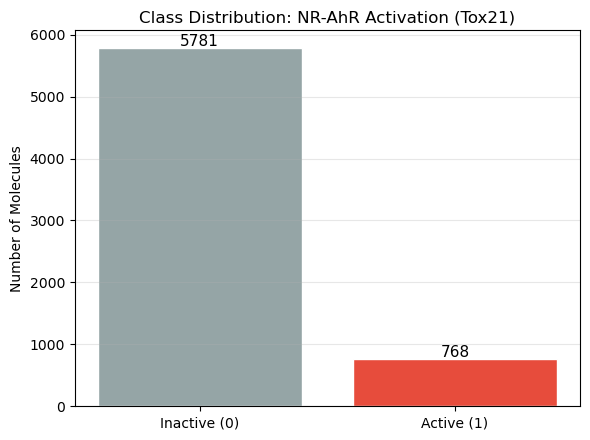

In [5]:
fig, ax = plt.subplots(figsize=(6, 4.5))
counts = [n_neg, n_pos]
bars = ax.bar(['Inactive (0)', 'Active (1)'], counts,
              color=['#95a5a6', '#e74c3c'], edgecolor='white')
for b, c in zip(bars, counts):
    ax.text(b.get_x() + b.get_width()/2, c + 30, str(c), ha='center', fontsize=11)
ax.set_title('Class Distribution: NR-AhR Activation (Tox21)')
ax.set_ylabel('Number of Molecules')
ax.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / 'class_distribution.png', dpi=120, bbox_inches='tight')
plt.show()


---
### 2.2 從 SMILES 到分子圖

與第一個範例相同，用 RDKit 把 SMILES 轉成原子特徵矩陣 $X$ 與鄰接矩陣 $A$ 。不同的是，Tox21 含有**鹽類與混合物**（SMILES 以 `.` 分隔多個片段），我們取**最大的分子片段**（去除反離子），以聚焦主要結構。

In [6]:
from rdkit.Chem.rdchem import HybridizationType

ATOM_SYMBOLS = ['C', 'N', 'O', 'F', 'S', 'Cl', 'Br', 'I', 'P']
HYBRIDIZATIONS = [HybridizationType.SP, HybridizationType.SP2, HybridizationType.SP3]

def _onehot(value, choices):
    return [1 if value == c else 0 for c in choices]

def largest_fragment(mol):
    """取最大分子片段並重新 sanitize (去除反離子/鹽類)"""
    frags = Chem.GetMolFrags(mol, asMols=True, sanitizeFrags=False)
    if len(frags) > 1:
        mol = max(frags, key=lambda m: m.GetNumAtoms())
    try:
        Chem.SanitizeMol(mol)
    except Exception:
        return None
    return mol

def atom_features(atom):
    """原子 -> 特徵向量 (27 維)"""
    sym = atom.GetSymbol()
    feats = []
    feats += _onehot(sym, ATOM_SYMBOLS)                       # 9
    feats += [1 if sym not in ATOM_SYMBOLS else 0]            # 1
    feats += _onehot(atom.GetDegree(), [0, 1, 2, 3, 4, 5])   # 6
    feats += [atom.GetFormalCharge()]                        # 1
    feats += _onehot(atom.GetHybridization(), HYBRIDIZATIONS) # 3
    feats += [1 if atom.GetIsAromatic() else 0]              # 1
    feats += _onehot(atom.GetTotalNumHs(), [0, 1, 2, 3, 4])  # 5
    feats += [1 if atom.IsInRing() else 0]                   # 1
    return np.array(feats, dtype='float32')

def smiles_to_graph(smiles):
    """SMILES -> (X, A)，取最大片段 (去鹽/反離子)"""
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None
    mol = largest_fragment(mol)
    if mol is None or mol.GetNumAtoms() == 0:
        return None
    n = mol.GetNumAtoms()
    X = np.stack([atom_features(a) for a in mol.GetAtoms()], axis=0)
    A = np.zeros((n, n), dtype='float32')
    for bond in mol.GetBonds():
        i, j = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
        A[i, j] = 1.0
        A[j, i] = 1.0
    return X, A

_X, _A = smiles_to_graph('CCO')
F = _X.shape[1]
print(f"原子特徵維度 F = {F}")
print(f"測試 (乙醇 CCO): {_X.shape[0]} 原子, A shape = {_A.shape}")


原子特徵維度 F = 27
測試 (乙醇 CCO): 3 原子, A shape = (3, 3)


---
### 3. 特徵化與 Padding

將所有分子轉為圖並 padding 到相同原子數。由於少數分子非常大（最多逾百個原子），我們**過濾掉原子數 > 50 的分子**（涵蓋約 95% 以上的資料），以控制記憶體與計算量。

In [7]:
MAX_ATOMS_LIMIT = 50

graphs, labels = [], []
smiles_used = []
n_fail, n_toobig = 0, 0
for smi, y in zip(df['smiles'], df[TASK]):
    g = smiles_to_graph(smi)
    if g is None:
        n_fail += 1
        continue
    if g[0].shape[0] > MAX_ATOMS_LIMIT:
        n_toobig += 1
        continue
    graphs.append(g)
    labels.append(y)
    smiles_used.append(smi)

MAX_ATOMS = max(X.shape[0] for X, A in graphs)
n_mol = len(graphs)
labels = np.array(labels, dtype='float32')
smiles_used = np.array(smiles_used, dtype=object)
print(f"解析失敗: {n_fail} 個; 過大(>{MAX_ATOMS_LIMIT}原子)而剔除: {n_toobig} 個")
print(f"最終使用分子數: {n_mol}")
print(f"實際最大原子數 MAX_ATOMS = {MAX_ATOMS}")
print(f"正例率: {100*labels.mean():.2f}%")


解析失敗: 7 個; 過大(>50原子)而剔除: 114 個
最終使用分子數: 6428
實際最大原子數 MAX_ATOMS = 50
正例率: 11.89%


In [8]:
# Padding + 節點遮罩
X_all = np.zeros((n_mol, MAX_ATOMS, F), dtype='float32')
A_all = np.zeros((n_mol, MAX_ATOMS, MAX_ATOMS), dtype='float32')
mask_all = np.zeros((n_mol, MAX_ATOMS, 1), dtype='float32')

for k, (X, A) in enumerate(graphs):
    n = X.shape[0]
    X_all[k, :n, :] = X
    A_all[k, :n, :n] = A
    mask_all[k, :n, 0] = 1.0

# GAT 使用「含自連接」的二元鄰接矩陣 (注意力在鄰居+自身間計算)
A_self = A_all + np.eye(MAX_ATOMS, dtype='float32')[None, :, :] * mask_all  # 僅真實原子加自連接
y_all = labels.reshape(-1, 1)
print(f"X_all: {X_all.shape}, A_self: {A_self.shape}, mask_all: {mask_all.shape}, y: {y_all.shape}")


X_all: (6428, 50, 27), A_self: (6428, 50, 50), mask_all: (6428, 50, 1), y: (6428, 1)


---
### 4. 資料分割與類別權重

以 **分層抽樣(stratify)** 進行 80/20 分割，確保訓練與測試集的正例比例一致。由於正例僅約 12%，訓練時使用 **class weight** 讓模型更關注少數類別。

In [9]:
idx = np.arange(n_mol)
idx_train, idx_test = train_test_split(idx, test_size=0.2, random_state=SEED,
                                       stratify=labels)

Xtr, Xte = X_all[idx_train], X_all[idx_test]
Atr, Ate = A_self[idx_train], A_self[idx_test]
Mtr, Mte = mask_all[idx_train], mask_all[idx_test]
ytr, yte = y_all[idx_train], y_all[idx_test]

# 類別權重 (反比於頻率)
pos = ytr.sum(); neg = len(ytr) - pos
class_weight = {0: len(ytr) / (2*neg), 1: len(ytr) / (2*pos)}
print(f"訓練集: {len(idx_train)} (正例 {int(pos)}), 測試集: {len(idx_test)} (正例 {int(yte.sum())})")
print(f"class_weight = {{0: {class_weight[0]:.3f}, 1: {class_weight[1]:.3f}}}")


訓練集: 5142 (正例 611), 測試集: 1286 (正例 153)
class_weight = {0: 0.567, 1: 4.208}


---
### 5. 從零實作 batched GAT（圖注意力）層

GCN 對所有鄰居一視同仁；**GAT** 則透過**注意力機制**自適應地學習每個鄰居的重要性權重 $\alpha_{ij}$ ：

$$
h_i' = \sigma\left( \sum_{j \in \mathcal{N}(i) \cup \{i\}} \alpha_{ij}\, W h_j \right)
$$

注意力係數由可學習的注意力向量計算，經 LeakyReLU 與 softmax 正規化：

$$
\alpha_{ij} = \mathrm{softmax}_j\left( \mathrm{LeakyReLU}\left( \vec{a}_{\mathrm{src}}^\top W h_i + \vec{a}_{\mathrm{dst}}^\top W h_j \right) \right)
$$

本實作支援 **多頭注意力(multi-head)**：多組獨立的注意力並行學習後再合併，提升穩定性與表達力。

In [10]:
class GATLayer(layers.Layer):
    """Batched 多頭圖注意力層 (GAT)。"""

    def __init__(self, units, heads=4, concat=True, activation='elu',
                 leaky_slope=0.2, **kwargs):
        super().__init__(**kwargs)
        self.units = units
        self.heads = heads
        self.concat = concat
        self.activation = keras.activations.get(activation)
        self.leaky = layers.LeakyReLU(leaky_slope)

    def build(self, input_shape):
        feat_dim = int(input_shape[0][-1])
        # 每個 head 一組權重
        self.W = self.add_weight(name='W', shape=(self.heads, feat_dim, self.units),
                                 initializer='glorot_uniform', trainable=True)
        self.a_src = self.add_weight(name='a_src', shape=(self.heads, self.units),
                                     initializer='glorot_uniform', trainable=True)
        self.a_dst = self.add_weight(name='a_dst', shape=(self.heads, self.units),
                                     initializer='glorot_uniform', trainable=True)

    def call(self, inputs):
        H, A = inputs                                   # H:(B,N,F)  A:(B,N,N) 含自連接
        Wh = tf.einsum('bnf,hfu->bnhu', H, self.W)      # (B,N,heads,units)
        e_src = tf.einsum('bnhu,hu->bnh', Wh, self.a_src)  # (B,N,heads)
        e_dst = tf.einsum('bnhu,hu->bnh', Wh, self.a_dst)  # (B,N,heads)
        # e[b,i,j,h] = LeakyReLU(e_src[b,i,h] + e_dst[b,j,h])
        e = self.leaky(e_src[:, :, None, :] + e_dst[:, None, :, :])  # (B,N,N,heads)
        # 僅在有邊處 (A>0) 計算注意力，其餘設為極小值
        adj_mask = (A > 0)[:, :, :, None]               # (B,N,N,1)
        e = tf.where(adj_mask, e, tf.fill(tf.shape(e), -1e9))
        alpha = tf.nn.softmax(e, axis=2)                # 對鄰居 j 正規化 (B,N,N,heads)
        out = tf.einsum('bijh,bjhu->bihu', alpha, Wh)   # (B,N,heads,units)
        if self.concat:
            out = tf.reshape(out, tf.concat([tf.shape(out)[:2], [self.heads*self.units]], 0))
        else:
            out = tf.reduce_mean(out, axis=2)           # 平均各 head (B,N,units)
        return self.activation(out)


def masked_mean_pool(args):
    H, mask = args
    summed = tf.reduce_sum(H * mask, axis=1)
    count = tf.reduce_sum(mask, axis=1)
    return summed / (count + 1e-8)

print("GATLayer 與 masked_mean_pool 已定義。")


GATLayer 與 masked_mean_pool 已定義。


---
### 6. 建立 GAT 分類模型

堆疊兩層 GAT（第一層多頭串接、第二層單頭平均），以 masked mean pooling 讀出分子表示，最後接 MLP + **sigmoid** 輸出活化機率。

In [11]:
def build_gat_classifier(max_atoms, n_features):
    X_in = keras.Input(shape=(max_atoms, n_features), name='node_features')
    A_in = keras.Input(shape=(max_atoms, max_atoms), name='adjacency_self')
    M_in = keras.Input(shape=(max_atoms, 1), name='node_mask')

    h = GATLayer(units=16, heads=4, concat=True)([X_in, A_in])   # -> (B,N,64)
    h = layers.Multiply()([h, M_in])
    h = GATLayer(units=32, heads=1, concat=False)([h, A_in])     # -> (B,N,32)
    h = layers.Multiply()([h, M_in])

    pooled = layers.Lambda(masked_mean_pool, name='readout')([h, M_in])
    z = layers.Dense(32, activation='relu')(pooled)
    z = layers.Dropout(0.3)(z)
    out = layers.Dense(1, activation='sigmoid', name='tox')(z)
    return keras.Model([X_in, A_in, M_in], out)

model = build_gat_classifier(MAX_ATOMS, F)
model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss='binary_crossentropy',
              metrics=[keras.metrics.AUC(name='auc'),
                       keras.metrics.AUC(name='prauc', curve='PR')])
model.summary()


Model: "model"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 node_features (InputLayer)     [(None, 50, 27)]     0           []                               
                                                                                                  
 adjacency_self (InputLayer)    [(None, 50, 50)]     0           []                               
                                                                                                  
 gat_layer (GATLayer)           (None, 50, 64)       1856        ['node_features[0][0]',          
                                                                  'adjacency_self[0][0]']         
                                                                                                  
 node_mask (InputLayer)         [(None, 50, 1)]      0           []                           

---
### 7. 訓練模型

以二元交叉熵損失訓練，套用 class weight 處理不平衡，並以 EarlyStopping 監控驗證集 AUC。

In [12]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor='val_auc', mode='max', patience=25,
                                  restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor='val_auc', mode='max', factor=0.5,
                                      patience=12, min_lr=1e-5),
]

history = model.fit(
    [Xtr, Atr, Mtr], ytr,
    validation_split=0.15,
    epochs=120,
    batch_size=32,
    class_weight=class_weight,
    callbacks=callbacks,
    verbose=0,
)

print(f"訓練完成，共 {len(history.history['loss'])} 個 epoch")
print(f"最佳驗證 AUC = {max(history.history['val_auc']):.4f}")


訓練完成，共 100 個 epoch
最佳驗證 AUC = 0.9091


### 7.1 訓練曲線

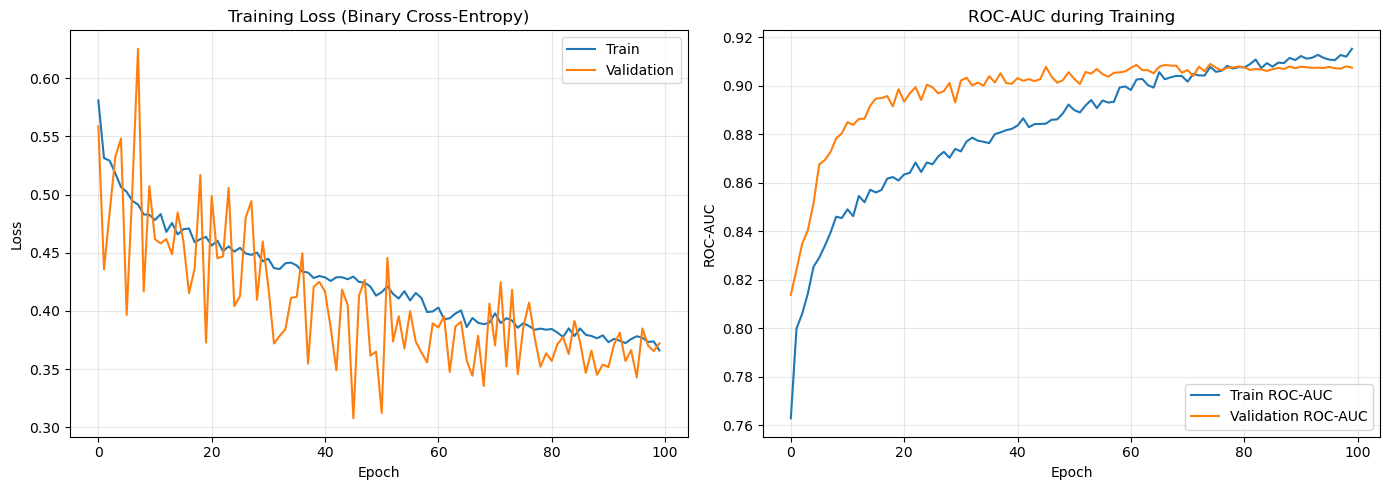

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history['loss'], label='Train')
axes[0].plot(history.history['val_loss'], label='Validation')
axes[0].set_title('Training Loss (Binary Cross-Entropy)')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(history.history['auc'], label='Train ROC-AUC')
axes[1].plot(history.history['val_auc'], label='Validation ROC-AUC')
axes[1].set_title('ROC-AUC during Training')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('ROC-AUC')
axes[1].legend(); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(FIG_DIR / 'training_curves.png', dpi=120, bbox_inches='tight')
plt.show()


---
### 8. 評估與基線比較

分類任務以 **ROC-AUC** 與 **PR-AUC（平均精確率）** 為主要指標（對不平衡資料較公允）。比較兩種方法：

1. **GAT**（本範例，圖注意力）
2. **分子描述子 + 隨機森林**（傳統化學資訊學基線）

In [14]:
# --- GAT 預測 ---
gat_prob = model.predict([Xte, Ate, Mte], verbose=0).ravel()
y_true = yte.ravel().astype(int)
auc_gat = roc_auc_score(y_true, gat_prob)
ap_gat = average_precision_score(y_true, gat_prob)

# --- 基線: RDKit 描述子 + 隨機森林 ---
def mol_descriptors(smiles):
    mol = Chem.MolFromSmiles(smiles)
    mol = largest_fragment(mol)
    return [Descriptors.MolWt(mol), Descriptors.MolLogP(mol), Descriptors.TPSA(mol),
            Descriptors.NumHDonors(mol), Descriptors.NumHAcceptors(mol),
            Descriptors.NumRotatableBonds(mol), Descriptors.NumAromaticRings(mol),
            Descriptors.FractionCSP3(mol), Descriptors.NumHeteroatoms(mol),
            Descriptors.RingCount(mol)]

D = np.array([mol_descriptors(s) for s in smiles_used], dtype='float32')
Dtr, Dte = D[idx_train], D[idx_test]
rf = RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=SEED, n_jobs=-1)
rf.fit(Dtr, ytr.ravel())
rf_prob = rf.predict_proba(Dte)[:, 1]
auc_rf = roc_auc_score(y_true, rf_prob)
ap_rf = average_precision_score(y_true, rf_prob)

base_rate = y_true.mean()
results = pd.DataFrame({
    'Model': ['GAT (graph attention)', 'Descriptors + Random Forest'],
    'ROC-AUC': [auc_gat, auc_rf],
    'PR-AUC': [ap_gat, ap_rf],
})
print("測試集表現比較 (NR-AhR 活化分類):\n")
print(results.to_string(index=False, float_format=lambda x: f'{x:.3f}'))
print(f"\n參考: 隨機猜測 ROC-AUC = 0.5; 正例基準率 (PR-AUC 下限) = {base_rate:.3f}")


測試集表現比較 (NR-AhR 活化分類):

                      Model  ROC-AUC  PR-AUC
      GAT (graph attention)    0.879   0.547
Descriptors + Random Forest    0.853   0.539

參考: 隨機猜測 ROC-AUC = 0.5; 正例基準率 (PR-AUC 下限) = 0.119


### 8.1 ROC 曲線與 PR 曲線

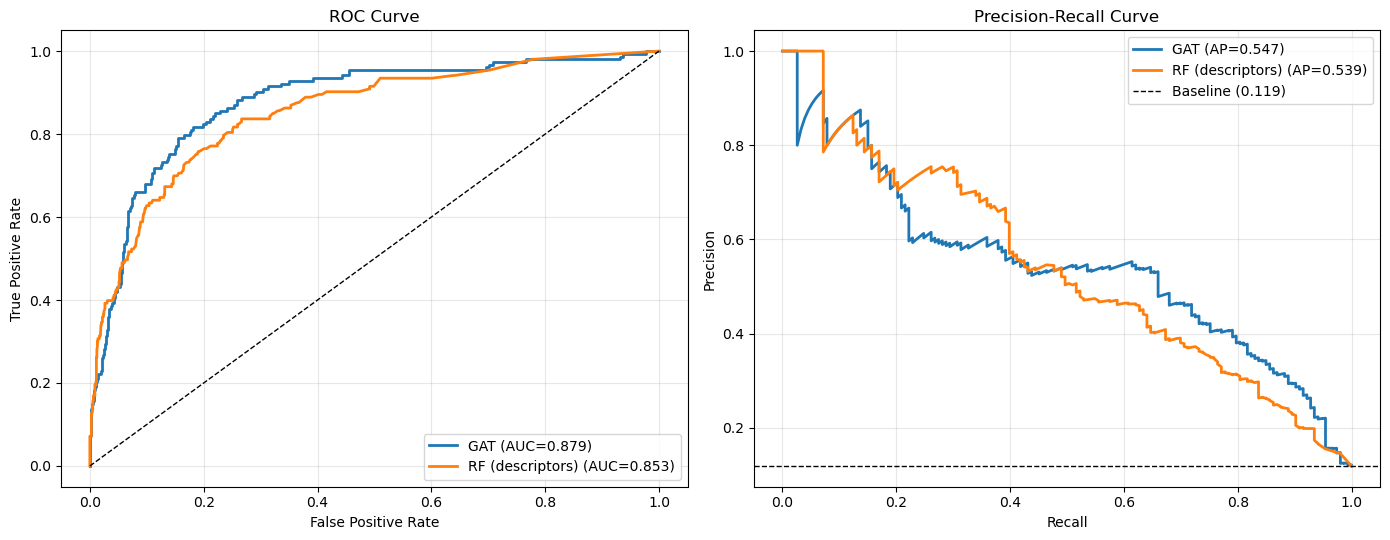

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# ROC
for name, prob, auc in [('GAT', gat_prob, auc_gat), ('RF (descriptors)', rf_prob, auc_rf)]:
    fpr, tpr, _ = roc_curve(y_true, prob)
    axes[0].plot(fpr, tpr, lw=2, label=f'{name} (AUC={auc:.3f})')
axes[0].plot([0, 1], [0, 1], 'k--', lw=1)
axes[0].set_title('ROC Curve'); axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate'); axes[0].legend(loc='lower right')
axes[0].grid(True, alpha=0.3)

# PR
for name, prob, ap in [('GAT', gat_prob, ap_gat), ('RF (descriptors)', rf_prob, ap_rf)]:
    prec, rec, _ = precision_recall_curve(y_true, prob)
    axes[1].plot(rec, prec, lw=2, label=f'{name} (AP={ap:.3f})')
axes[1].axhline(base_rate, color='k', ls='--', lw=1, label=f'Baseline ({base_rate:.3f})')
axes[1].set_title('Precision-Recall Curve'); axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision'); axes[1].legend(loc='upper right')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(FIG_DIR / 'roc_pr_curves.png', dpi=120, bbox_inches='tight')
plt.show()


### 8.2 混淆矩陣與分類報告（GAT, 閾值 0.5）

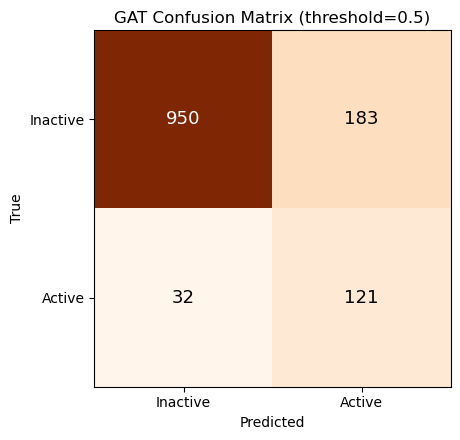

              precision    recall  f1-score   support

    Inactive       0.97      0.84      0.90      1133
      Active       0.40      0.79      0.53       153

    accuracy                           0.83      1286
   macro avg       0.68      0.81      0.71      1286
weighted avg       0.90      0.83      0.85      1286



In [16]:
gat_pred = (gat_prob >= 0.5).astype(int)
cm = confusion_matrix(y_true, gat_pred)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.imshow(cm, cmap='Oranges')
for i in range(2):
    for j in range(2):
        ax.text(j, i, int(cm[i, j]), ha='center', va='center',
                color='white' if cm[i, j] > cm.max()/2 else 'black', fontsize=13)
ax.set_title('GAT Confusion Matrix (threshold=0.5)')
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
ax.set_xticks([0, 1]); ax.set_xticklabels(['Inactive', 'Active'])
ax.set_yticks([0, 1]); ax.set_yticklabels(['Inactive', 'Active'])
plt.tight_layout()
plt.savefig(FIG_DIR / 'confusion_matrix.png', dpi=120, bbox_inches='tight')
plt.show()

print(classification_report(y_true, gat_pred, target_names=['Inactive', 'Active']))


### 8.3 範例分子預測

展示測試集中模型最有信心判定為「活化(有毒)」的幾個分子結構與其預測機率。

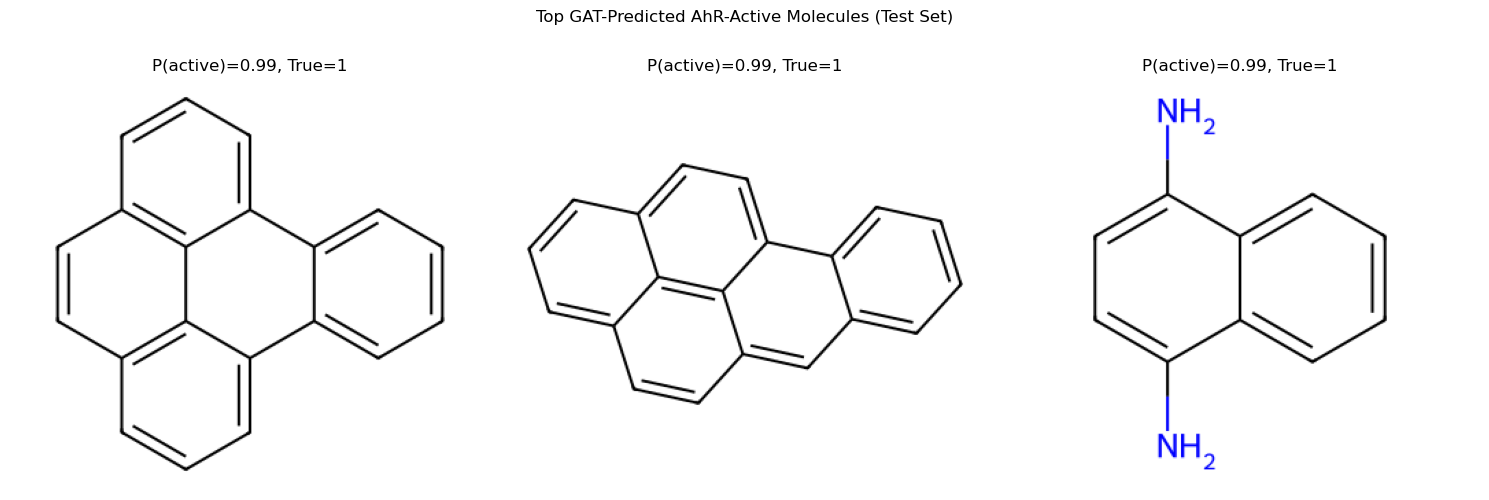

In [17]:
top_idx = np.argsort(gat_prob)[::-1][:3]   # 預測機率最高的 3 個
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, t in zip(axes, top_idx):
    smi = smiles_used[idx_test][t]
    mol = Chem.MolFromSmiles(smi)
    mol = largest_fragment(mol)
    d = rdMolDraw2D.MolDraw2DCairo(350, 300)
    d.DrawMolecule(mol); d.FinishDrawing()
    tmp = FIG_DIR / f'_tmp_{t}.png'
    with open(tmp, 'wb') as fh:
        fh.write(d.GetDrawingText())
    ax.imshow(plt.imread(tmp)); ax.axis('off')
    ax.set_title(f'P(active)={gat_prob[t]:.2f}, True={int(y_true[t])}')
    os.remove(tmp)
plt.suptitle('Top GAT-Predicted AhR-Active Molecules (Test Set)', y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / 'example_molecules.png', dpi=120, bbox_inches='tight')
plt.show()


---
### 8.4 決策閾值調整與精確率-召回率取捨

第 8.2 節的分類報告使用預設閾值 0.5。但在**不平衡的安全篩選**情境中，0.5 不一定是最佳決策點：

- **安全導向（寧可多篩、不可漏檢）**：調**低**閾值 → 提高 Recall（抓到更多毒性分子），代價是 Precision 下降（更多誤報）。
- **精準導向（節省後續昂貴實驗）**：調**高**閾值 → 提高 Precision，代價是 Recall 下降（可能漏檢）。

由於**改變閾值不需要重新訓練**（模型輸出的機率不變），我們可以掃描不同閾值，觀察 Precision / Recall / F1 的變化，並依實務需求選擇**營運點(operating point)**。


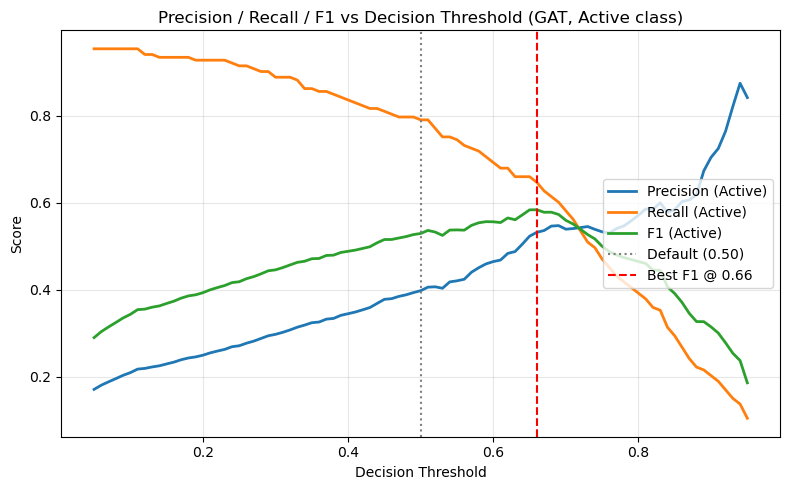

預設閾值 0.50 : Precision=0.398, Recall=0.791, F1=0.530
最佳 F1 閾值 0.66: Precision=0.532, Recall=0.647, F1=0.584
安全導向 (Recall≥0.90) 閾值 0.29: Precision=0.294, Recall=0.902 (多篩以降低漏檢)


In [19]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = np.linspace(0.05, 0.95, 91)
prec_arr, rec_arr, f1_arr = [], [], []
for t in thresholds:
    pred_t = (gat_prob >= t).astype(int)
    prec_arr.append(precision_score(y_true, pred_t, zero_division=0))
    rec_arr.append(recall_score(y_true, pred_t, zero_division=0))
    f1_arr.append(f1_score(y_true, pred_t, zero_division=0))
prec_arr = np.array(prec_arr); rec_arr = np.array(rec_arr); f1_arr = np.array(f1_arr)

best_i = int(np.argmax(f1_arr))
best_t = thresholds[best_i]
i_def = int(np.argmin(np.abs(thresholds - 0.5)))

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(thresholds, prec_arr, lw=2, label='Precision (Active)')
ax.plot(thresholds, rec_arr, lw=2, label='Recall (Active)')
ax.plot(thresholds, f1_arr, lw=2, label='F1 (Active)')
ax.axvline(0.5, color='gray', ls=':', lw=1.5, label='Default (0.50)')
ax.axvline(best_t, color='red', ls='--', lw=1.5, label=f'Best F1 @ {best_t:.2f}')
ax.set_xlabel('Decision Threshold'); ax.set_ylabel('Score')
ax.set_title('Precision / Recall / F1 vs Decision Threshold (GAT, Active class)')
ax.legend(loc='center right'); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / 'threshold_tuning.png', dpi=120, bbox_inches='tight')
plt.show()

print(f"預設閾值 0.50 : Precision={prec_arr[i_def]:.3f}, Recall={rec_arr[i_def]:.3f}, F1={f1_arr[i_def]:.3f}")
print(f"最佳 F1 閾值 {best_t:.2f}: Precision={prec_arr[best_i]:.3f}, Recall={rec_arr[best_i]:.3f}, F1={f1_arr[best_i]:.3f}")

hi = np.where(rec_arr >= 0.90)[0]
if len(hi):
    j = hi[np.argmax(prec_arr[hi])]
    print(f"安全導向 (Recall≥0.90) 閾值 {thresholds[j]:.2f}: "
          f"Precision={prec_arr[j]:.3f}, Recall={rec_arr[j]:.3f} (多篩以降低漏檢)")


---
### 8.5 注意力權重視覺化：模型在看哪些原子？

GAT 相對 GCN 的最大優勢是**可解釋性**：注意力係數 $\alpha_{ij}$ 本身就能告訴我們「模型認為哪些原子對預測最重要」。

我們直接取出**訓練好的第一層 GAT** 的權重 $(W, \vec{a}_{\mathrm{src}}, \vec{a}_{\mathrm{dst}})$ ，對單一分子重算注意力係數，並將每個原子**所接收到的總注意力**（ $\sum_i \alpha_{ij}$ ，對多頭取平均）映射回分子結構上色。顏色越深代表該原子獲得越多關注。

> [!NOTE]
> 若模型真的學到「稠環芳香 → AhR 活化」，那麼在已知的 AhR 活化劑上，**稠環芳香區域的原子應獲得較高的注意力**。


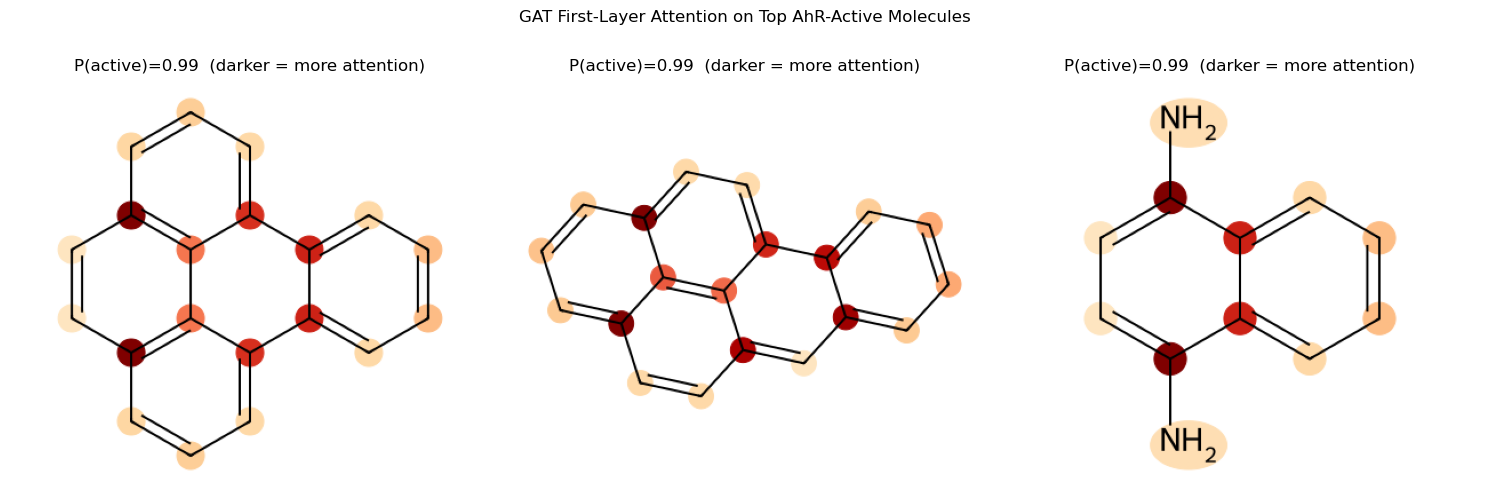

深色原子 = 接收較多注意力。觀察稠環芳香區域是否被模型重點關注。


In [20]:
import matplotlib.cm as cm

def atom_attention(smiles, gat_layer, leaky_slope=0.2):
    """用訓練好的 GAT 層權重，重算單一分子每個原子接收到的平均注意力。"""
    g = smiles_to_graph(smiles)
    if g is None:
        return None
    X, A = g
    n = X.shape[0]
    A_sl = A + np.eye(n, dtype='float32')          # 含自連接 (與訓練一致)
    W = gat_layer.W.numpy()                          # (heads, F, units)
    a_src = gat_layer.a_src.numpy()                  # (heads, units)
    a_dst = gat_layer.a_dst.numpy()
    heads = W.shape[0]
    att_recv = np.zeros(n, dtype='float32')
    for h in range(heads):
        Wh = X @ W[h]                                # (n, units)
        e = (Wh @ a_src[h])[:, None] + (Wh @ a_dst[h])[None, :]   # e[i,j]
        e = np.where(e > 0, e, leaky_slope * e)      # LeakyReLU
        e = np.where(A_sl > 0, e, -1e9)              # 僅鄰居(+自身)
        e = e - e.max(axis=1, keepdims=True)
        alpha = np.exp(e); alpha /= alpha.sum(axis=1, keepdims=True)  # softmax over j
        att_recv += alpha.sum(axis=0)                # 原子 j 接收到的總注意力
    return att_recv / heads

def draw_attention(smiles, gat_layer, prob):
    att = atom_attention(smiles, gat_layer)
    mol = largest_fragment(Chem.MolFromSmiles(smiles))
    n = mol.GetNumAtoms()
    att = att[:n]
    norm = (att - att.min()) / (att.max() - att.min() + 1e-8)
    cmap = cm.get_cmap('OrRd')
    colors = {i: cmap(0.15 + 0.85 * float(norm[i]))[:3] for i in range(n)}
    d = rdMolDraw2D.MolDraw2DCairo(420, 360)
    rdMolDraw2D.PrepareAndDrawMolecule(
        d, mol, highlightAtoms=list(range(n)), highlightAtomColors=colors,
        highlightBonds=[])
    d.FinishDrawing()
    return d.GetDrawingText()

gat1 = model.get_layer('gat_layer')
top3 = np.argsort(gat_prob)[::-1][:3]
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, t in zip(axes, top3):
    smi = smiles_used[idx_test][t]
    png = draw_attention(smi, gat1, gat_prob[t])
    tmp = FIG_DIR / f'_att_{t}.png'
    with open(tmp, 'wb') as fh:
        fh.write(png)
    ax.imshow(plt.imread(tmp)); ax.axis('off')
    ax.set_title(f'P(active)={gat_prob[t]:.2f}  (darker = more attention)')
    os.remove(tmp)
plt.suptitle('GAT First-Layer Attention on Top AhR-Active Molecules', y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / 'attention_maps.png', dpi=120, bbox_inches='tight')
plt.show()
print("深色原子 = 接收較多注意力。觀察稠環芳香區域是否被模型重點關注。")


---
### 8.6 與 GCN 架構對照

前面我們已和**傳統描述子 + 隨機森林**比較。這裡再補上與第一個範例所用的 **GCN（圖卷積）** 架構的**同場比較**，以凸顯注意力機制帶來的差異。

兩者的關鍵差別（見第 4.1 節）：

- **GCN**：以**正規化鄰接矩陣** $\hat{A} = \tilde{D}^{-1/2}(A+I)\tilde{D}^{-1/2}$ 聚合鄰居，權重由圖結構**固定**。
- **GAT**：以**可學習的注意力係數** $\alpha_{ij}$ 聚合，權重隨資料**自適應**。

為公平比較，GCN 使用與 GAT **相同的資料切分、類別權重與訓練設定**，只差在聚合方式。


In [21]:
class GCNLayer(layers.Layer):
    """Batched 圖卷積層：以預先正規化的鄰接矩陣聚合鄰居。"""
    def __init__(self, units, activation='relu', **kwargs):
        super().__init__(**kwargs)
        self.units = units
        self.activation = keras.activations.get(activation)

    def build(self, input_shape):
        feat_dim = int(input_shape[0][-1])
        self.W = self.add_weight(name='W', shape=(feat_dim, self.units),
                                 initializer='glorot_uniform', trainable=True)
        self.b = self.add_weight(name='b', shape=(self.units,),
                                 initializer='zeros', trainable=True)

    def call(self, inputs):
        H, A_hat = inputs                 # A_hat 已正規化
        agg = tf.matmul(A_hat, H)         # 聚合鄰居 (B,N,F)
        out = tf.matmul(agg, self.W) + self.b
        return self.activation(out)


def normalize_adj(A):
    """對稱正規化 D^-1/2 (A+I) D^-1/2 (A 已含自連接)。"""
    deg = A.sum(axis=-1)                                   # (B,N)
    dinv = np.where(deg > 0, deg ** -0.5, 0.0).astype('float32')
    return A * dinv[:, :, None] * dinv[:, None, :]

A_hat_tr = normalize_adj(Atr)
A_hat_te = normalize_adj(Ate)

def build_gcn_classifier(max_atoms, n_features):
    X_in = keras.Input(shape=(max_atoms, n_features), name='node_features')
    A_in = keras.Input(shape=(max_atoms, max_atoms), name='adjacency_norm')
    M_in = keras.Input(shape=(max_atoms, 1), name='node_mask')
    h = GCNLayer(64)([X_in, A_in]); h = layers.Multiply()([h, M_in])
    h = GCNLayer(32)([h, A_in]);    h = layers.Multiply()([h, M_in])
    pooled = layers.Lambda(masked_mean_pool, name='readout')([h, M_in])
    z = layers.Dense(32, activation='relu')(pooled)
    z = layers.Dropout(0.3)(z)
    out = layers.Dense(1, activation='sigmoid', name='tox')(z)
    return keras.Model([X_in, A_in, M_in], out)

tf.random.set_seed(SEED)
gcn = build_gcn_classifier(MAX_ATOMS, F)
gcn.compile(optimizer=keras.optimizers.Adam(1e-3), loss='binary_crossentropy',
            metrics=[keras.metrics.AUC(name='auc')])
gcn_cb = [keras.callbacks.EarlyStopping(monitor='val_auc', mode='max', patience=25,
                                        restore_best_weights=True),
          keras.callbacks.ReduceLROnPlateau(monitor='val_auc', mode='max', factor=0.5,
                                            patience=12, min_lr=1e-5)]
gcn_hist = gcn.fit([Xtr, A_hat_tr, Mtr], ytr, validation_split=0.15, epochs=120,
                   batch_size=32, class_weight=class_weight, callbacks=gcn_cb, verbose=0)

gcn_prob = gcn.predict([Xte, A_hat_te, Mte], verbose=0).ravel()
auc_gcn = roc_auc_score(y_true, gcn_prob)
ap_gcn = average_precision_score(y_true, gcn_prob)
print(f"GCN 訓練完成 ({len(gcn_hist.history['loss'])} epoch), 最佳驗證 AUC = {max(gcn_hist.history['val_auc']):.4f}")

compare = pd.DataFrame({
    'Model': ['GAT (graph attention)', 'GCN (graph convolution)', 'Descriptors + Random Forest'],
    'ROC-AUC': [auc_gat, auc_gcn, auc_rf],
    'PR-AUC':  [ap_gat, ap_gcn, ap_rf],
})
print("\n三方法測試集比較 (NR-AhR):\n")
print(compare.to_string(index=False, float_format=lambda x: f'{x:.3f}'))
print(f"\n參考: 隨機 ROC-AUC=0.5; 正例基準率 (PR-AUC 下限)={base_rate:.3f}")


GCN 訓練完成 (120 epoch), 最佳驗證 AUC = 0.9205

三方法測試集比較 (NR-AhR):

                      Model  ROC-AUC  PR-AUC
      GAT (graph attention)    0.879   0.547
    GCN (graph convolution)    0.891   0.606
Descriptors + Random Forest    0.853   0.539

參考: 隨機 ROC-AUC=0.5; 正例基準率 (PR-AUC 下限)=0.119


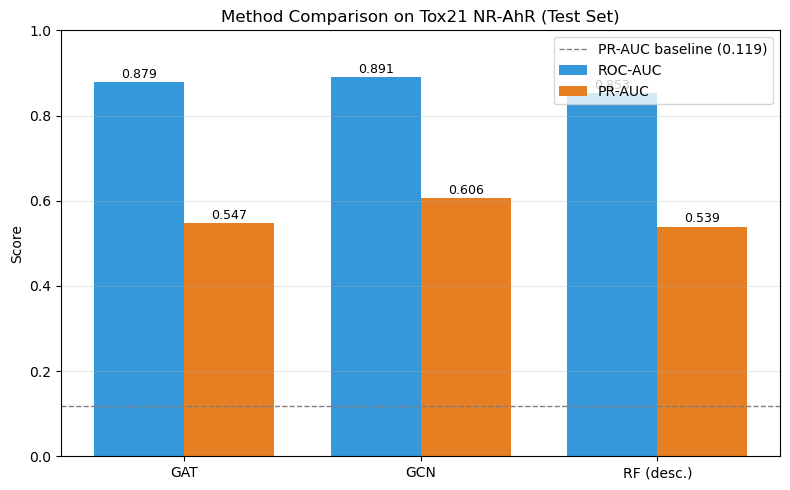

In [22]:
fig, ax = plt.subplots(figsize=(8, 5))
models = ['GAT', 'GCN', 'RF (desc.)']
roc_vals = [auc_gat, auc_gcn, auc_rf]
pr_vals = [ap_gat, ap_gcn, ap_rf]
x = np.arange(len(models)); w = 0.38
b1 = ax.bar(x - w/2, roc_vals, w, label='ROC-AUC', color='#3498db')
b2 = ax.bar(x + w/2, pr_vals, w, label='PR-AUC', color='#e67e22')
ax.axhline(base_rate, color='gray', ls='--', lw=1, label=f'PR-AUC baseline ({base_rate:.3f})')
for bars in (b1, b2):
    for b in bars:
        ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.01,
                f'{b.get_height():.3f}', ha='center', fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(models)
ax.set_ylim(0, 1.0); ax.set_ylabel('Score')
ax.set_title('Method Comparison on Tox21 NR-AhR (Test Set)')
ax.legend(loc='upper right'); ax.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / 'method_comparison_bar.png', dpi=120, bbox_inches='tight')
plt.show()


**討論：更複雜的架構不一定更好**

本次實驗中，**兩種 GNN（GAT 與 GCN）都明顯優於描述子 + 隨機森林**，顯示「從分子圖直接學習表示」確實有效。然而值得注意的是：

- 在**這個任務與切分**上，較簡單的 **GCN 反而略勝 GAT**（ROC-AUC 0.891 vs 0.879、PR-AUC 0.606 vs 0.547）。
- GAT 擁有更強的理論表達力與更多參數，但在**中小型資料集**上，額外的注意力參數**更難訓練、也更容易過擬合**，優勢未必能發揮。

> [!IMPORTANT]
> 這是機器學習的通則：**模型複雜度要與資料規模匹配**。GAT 的核心價值不只在準確率，更在於**可解釋性**（第 8.5 節的注意力視覺化）——這是 GCN 無法直接提供的。實務上應同時考量**效能、資料量、可解釋性與計算成本**來選擇架構。


---
### 9. 模型儲存

In [18]:
weights_path = MODEL_DIR / 'gat_toxicity'
model.save_weights(str(weights_path))
print(f"✓ GAT 模型權重已儲存至: {weights_path}.*")


✓ GAT 模型權重已儲存至: d:\MyGit\ChemE-3590\Part_4\Unit18\outputs\P4_Unit18_Example_Molecular_Toxicity\models\gat_toxicity.*


---
### 10. 總結

本 Notebook 以真實的 **Tox21 毒理學資料集**，示範了 GNN 在**化工/環境工程**的重要應用 — **分子毒性分類**：

1. **分類任務**：預測分子是否活化芳香烴受體(AhR)，與第一個範例的回歸任務互補
2. **GAT 架構**：從零實作圖注意力層，讓模型自適應加權不同鄰居（原子）的重要性
3. **類別不平衡處理**：正例僅約 12%，以 class weight、ROC-AUC、PR-AUC 正確評估
4. **基線比較**：GAT vs 描述子 + 隨機森林

#### 核心收穫
- GNN 不只能做回歸，也能做**分類**（只要把輸出層換成 sigmoid + 交叉熵）
- **注意力機制(GAT)** 讓模型自動辨識對毒性最關鍵的子結構
- 面對不平衡資料，**ROC-AUC / PR-AUC** 比準確率更能反映真實表現
- 分子毒性篩選對**製程安全、綠色化學、環境風險評估**有實際價值

#### 延伸練習
- 將 12 個 Tox21 任務改為**多任務學習**（multi-task）共享圖表示
- 加入**邊特徵(鍵級)** 或使用 MPNN
- 以**注意力權重視覺化**找出致毒的關鍵子結構
- 嘗試 scaffold split 評估對新骨架的泛化能力

---

**課程資訊**
- 課程名稱：AI在化工上之應用
- 課程單元：Unit18 - GNN 應用實例：分子毒性分類 (GAT)
- 課程製作：逢甲大學 化工系 智慧程序系統工程實驗室
- 授課教師：莊曜禎 助理教授
- 更新日期：2026-11-15

**課程授權 [CC BY-NC-SA 4.0]**
 - 本教材遵循 [創用CC 姓名標示-非商業性-相同方式分享 4.0 國際 (CC BY-NC-SA 4.0)](https://creativecommons.org/licenses/by-nc-sa/4.0/deed.zh) 授權。
